<a href="https://colab.research.google.com/github/sayalimane5772-art/hellogitworld/blob/master/Web_Traffic_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Web Traffic Analytics
## Objective
Analyze sample website traffic data to understand user behavior, traffic sources, page views, session duration, bounce rate, and conversions.

**Note:** This is a practice dataset created for this project. It is not real website analytics data.

## 1. Import libraries and load the data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('web_traffic_data.csv')
df.head()

,Date,Source,Page,Page_Views,Sessions,Avg_Session_Duration_Sec,Bounce_Rate_Pct,Conversions
0,2026-09-01,Organic Search,/home,320,180,145,32,18
1,2026-09-02,Social Media,/campaign,210,130,95,48,9
2,2026-09-03,Direct,/donate,180,105,110,41,15
3,2026-09-04,Referral,/about,95,60,80,55,3
4,2026-09-05,Organic Search,/education,260,150,135,35,14


## 2. Check data quality

In [3]:
print('Rows and columns:', df.shape)
print('\nMissing values:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df.info()

Rows and columns: (12, 8)

Missing values:
Date                        0
Source                      0
Page                        0
Page_Views                  0
Sessions                    0
Avg_Session_Duration_Sec    0
Bounce_Rate_Pct             0
Conversions                 0
dtype: int64

Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Date                      12 non-null     object
 1   Source                    12 non-null     object
 2   Page                      12 non-null     object
 3   Page_Views                12 non-null     int64 
 4   Sessions                  12 non-null     int64 
 5   Avg_Session_Duration_Sec  12 non-null     int64 
 6   Bounce_Rate_Pct           12 non-null     int64 
 7   Conversions               12 non-null     int64 
dtypes: int64(5), object(3)
memory usage: 9

## 3. Key metrics

In [4]:
total_page_views = df['Page_Views'].sum()
total_sessions = df['Sessions'].sum()
avg_duration = df['Avg_Session_Duration_Sec'].mean()
avg_bounce = df['Bounce_Rate_Pct'].mean()
total_conversions = df['Conversions'].sum()

print('Total page views:', total_page_views)
print('Total sessions:', total_sessions)
print('Average session duration (seconds):', round(avg_duration, 2))
print('Average bounce rate (%):', round(avg_bounce, 2))
print('Total conversions:', total_conversions)

Total page views: 2420
Total sessions: 1443
Average session duration (seconds): 115.83
Average bounce rate (%): 39.75
Total conversions: 151


## 4. Traffic source analysis

In [5]:
source_summary = df.groupby('Source').agg(
    Sessions=('Sessions', 'sum'),
    Page_Views=('Page_Views', 'sum'),
    Conversions=('Conversions', 'sum'),
    Avg_Bounce_Rate=('Bounce_Rate_Pct', 'mean')
).sort_values('Sessions', ascending=False)
source_summary

,Sessions,Page_Views,Conversions,Avg_Bounce_Rate
Source,,,,
Organic Search,505,890,57,32.333333
Social Media,425,690,33,46.000000
Direct,220,370,27,40.000000
Email,165,265,27,27.500000
Referral,128,205,7,53.500000


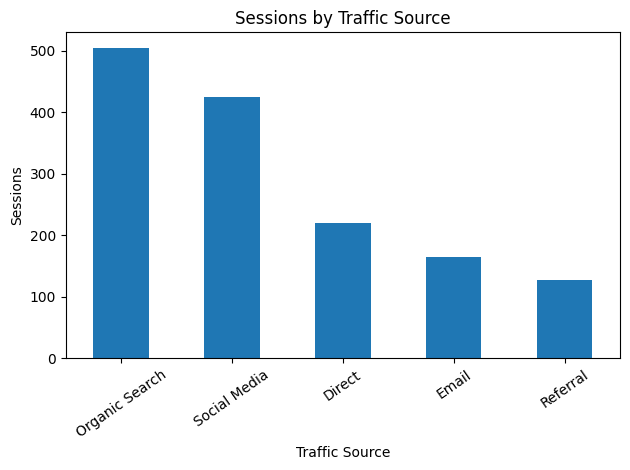

In [6]:
source_summary['Sessions'].plot(kind='bar', title='Sessions by Traffic Source', ylabel='Sessions', xlabel='Traffic Source', rot=35)
plt.tight_layout()
plt.show()

## 5. Popular pages and drop-off signals

In [7]:
page_summary = df.groupby('Page').agg(
    Page_Views=('Page_Views', 'sum'),
    Sessions=('Sessions', 'sum'),
    Avg_Bounce_Rate=('Bounce_Rate_Pct', 'mean'),
    Conversions=('Conversions', 'sum')
).sort_values('Page_Views', ascending=False)
page_summary

,Page_Views,Sessions,Avg_Bounce_Rate,Conversions
Page,,,,
/donate,755,445,31.5,67
/campaign,690,425,46.0,33
/home,510,295,35.5,30
/education,370,218,43.5,18
/about,95,60,55.0,3


A high bounce rate can be a signal that visitors leave quickly, but it does not prove the page is bad by itself. Review the page content and user journey before deciding what to change.

## 6. Findings and recommendations

- Compare traffic sources to see which channels bring the most sessions and conversions.
- Review pages with higher bounce rates to see whether the page matches visitor expectations.
- Improve the donation or campaign page call-to-action if visitors visit but do not convert.
- Check the user journey from landing page to donation page to find where users stop.
- Use real Google Analytics data for a real business decision; this sample dataset is only for practice.

## Conclusion
This project summarizes website traffic and highlights useful metrics for understanding user behavior. The sample data helps practice basic analysis with pandas and charts.